In [1]:
import os, torch
ON_KAGGLE = os.path.isdir("/kaggle/working")
WORK = "/kaggle/working/waste-sorter" if ON_KAGGLE else "/content/waste-sorter"
os.makedirs(WORK + "/wastesort", exist_ok=True)
os.chdir(WORK)
print("Working in", WORK)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE - turn the GPU on, or this will take days!")

Working in /kaggle/working/waste-sorter
GPU: Tesla T4


## 1. The code
The next cells just write the project's Python files to disk.

In [2]:
%%writefile wastesort/__init__.py
"""Waste sorter: a from-scratch CNN detector + CNN classifier (no pretrained weights)."""

Writing wastesort/__init__.py


In [3]:
%%writefile wastesort/config.py
"""Shared settings. Change things here, not scattered through the code."""

# The four things we sort. The order matters: it is the class id used everywhere.
CLASSES = ["glass_bottle", "paper_cup", "plastic_bottle", "metal_can"]
NICE_NAMES = ["Glass bottle", "Paper cup", "Plastic bottle", "Metal can"]
# Box colours (R, G, B) for drawing.
COLORS = [(46, 160, 67), (219, 109, 40), (56, 132, 244), (163, 113, 247)]

UNKNOWN = 9          # class id for "an object, but we don't know which of the 4" (detector only)

DET_SIZE = 416       # detector input size (pixels, longest side)
DET_STRIDE = 8       # detector output is 1/8 of the input resolution
CLS_SIZE = 128       # classifier input size
CLS_STORE = 144      # classifier crops are stored a bit larger so we can random-crop

# Kaggle datasets we use (all public, all free). See README for licences.
DATASETS = {
    "drinking": "arkadiyhacks/drinking-waste-classification",
    "vn": "mrgetshjtdone/vn-trash-classification",
    "household": "alistairking/recyclable-and-household-waste-classification",
    "cups": "vencerlanz09/plastic-and-paper-cups-synthetic-image-dataset",
    "taco": "vencerlanz09/taco-dataset-yolo-format",
}

Writing wastesort/config.py


In [4]:
%%writefile wastesort/models.py
"""The two CNNs, written from scratch (plain PyTorch layers, random initial weights).

  WasteDetector    finds objects: "there is *something* here, and this is its box"
  WasteClassifier  looks at one cropped object and says which of the 4 classes it is
"""
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.ops import nms

from .config import CLASSES, DET_STRIDE


class ConvBN(nn.Sequential):
    """Convolution -> batch-norm -> SiLU activation: the basic building brick."""

    def __init__(self, cin, cout, k=3, stride=1, act=True):
        super().__init__(
            nn.Conv2d(cin, cout, k, stride, k // 2, bias=False),
            nn.BatchNorm2d(cout),
            nn.SiLU(inplace=True) if act else nn.Identity(),
        )


class ResBlock(nn.Module):
    """Two 3x3 convolutions with a skip connection (as in ResNet)."""

    def __init__(self, cin, cout, stride=1):
        super().__init__()
        self.conv1 = ConvBN(cin, cout, 3, stride)
        self.conv2 = ConvBN(cout, cout, 3, act=False)
        self.skip = nn.Identity() if stride == 1 and cin == cout else ConvBN(cin, cout, 1, stride, act=False)

    def forward(self, x):
        return F.silu(self.conv2(self.conv1(x)) + self.skip(x))


def stage(cin, cout, blocks, stride=2):
    return nn.Sequential(ResBlock(cin, cout, stride), *[ResBlock(cout, cout) for _ in range(blocks - 1)])


def init_weights(model):
    for m in model.modules():
        if isinstance(m, nn.Conv2d):
            nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
        elif isinstance(m, nn.Linear):
            nn.init.trunc_normal_(m.weight, std=0.02)
            nn.init.zeros_(m.bias)


# ----------------------------------------------------------------------------- classifier
class WasteClassifier(nn.Module):
    """Small ResNet-style classifier. Input 3x128x128 -> 4 class scores. ~2.8M weights."""

    def __init__(self, num_classes=len(CLASSES), width=(32, 64, 128, 256), dropout=0.3):
        super().__init__()
        w = width
        self.features = nn.Sequential(
            ConvBN(3, w[0], 3, 2),          # 128 -> 64
            ConvBN(w[0], w[0], 3),
            stage(w[0], w[1], 2),           # 64 -> 32
            stage(w[1], w[2], 2),           # 32 -> 16
            stage(w[2], w[3], 2),           # 16 -> 8
            stage(w[3], w[3], 1),           # 8 -> 4
        )
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(dropout), nn.Linear(w[3], num_classes))
        init_weights(self)

    def forward(self, x):
        return self.head(self.features(x))


# ----------------------------------------------------------------------------- detector
class WasteDetector(nn.Module):
    """Anchor-free single-shot detector in the style of CenterNet. ~3.5M weights.

    A backbone shrinks the image to 1/8, 1/16 and 1/32 size; a small feature pyramid
    merges those back into one 1/8-size map. For every cell of that map the head says:
        channel 0    is an object centred here?   (heat-map, logit)
        channel 1-2  where exactly inside the cell is the centre (0..1)
        channel 3-4  log of box width / height, measured in cells
    It is class-agnostic: it only finds objects, the classifier names them.
    """

    def __init__(self, width=(32, 64, 128, 192, 256), neck=96):
        super().__init__()
        w = width
        self.stem = nn.Sequential(ConvBN(3, w[0], 3, 2), ConvBN(w[0], w[1], 3, 2), ResBlock(w[1], w[1]))  # 1/4
        self.c3 = stage(w[1], w[2], 2)      # 1/8
        self.c4 = stage(w[2], w[3], 2)      # 1/16
        self.c5 = stage(w[3], w[4], 2)      # 1/32
        self.l3, self.l4, self.l5 = ConvBN(w[2], neck, 1), ConvBN(w[3], neck, 1), ConvBN(w[4], neck, 1)
        self.p4, self.p3 = ConvBN(neck, neck, 3), ConvBN(neck, neck, 3)
        self.head = nn.Sequential(ConvBN(neck, neck, 3), ConvBN(neck, neck, 3), nn.Conv2d(neck, 5, 1))
        init_weights(self)
        nn.init.constant_(self.head[-1].bias, 0.0)
        nn.init.constant_(self.head[-1].bias[0:1], -2.19)   # start by predicting "no object" almost everywhere
        nn.init.constant_(self.head[-1].bias[3:5], 1.5)     # start with boxes ~4.5 cells wide

    def forward(self, x):
        c3 = self.c3(self.stem(x))
        c4 = self.c4(c3)
        c5 = self.c5(c4)
        p5 = self.l5(c5)
        p4 = self.p4(self.l4(c4) + F.interpolate(p5, size=c4.shape[-2:], mode="nearest"))
        p3 = self.p3(self.l3(c3) + F.interpolate(p4, size=c3.shape[-2:], mode="nearest"))
        return self.head(p3)


def decode_boxes(out, stride=DET_STRIDE):
    """Turn the raw head output [B,5,H,W] into boxes [B,H,W,4] (x1,y1,x2,y2 in input pixels)."""
    b, _, h, w = out.shape
    ys, xs = torch.meshgrid(torch.arange(h, device=out.device), torch.arange(w, device=out.device), indexing="ij")
    cx = (xs + torch.sigmoid(out[:, 1])) * stride
    cy = (ys + torch.sigmoid(out[:, 2])) * stride
    bw = torch.exp(out[:, 3].clamp(-4, 6)) * stride
    bh = torch.exp(out[:, 4].clamp(-4, 6)) * stride
    return torch.stack([cx - bw / 2, cy - bh / 2, cx + bw / 2, cy + bh / 2], dim=-1)


@torch.no_grad()
def detections(out, conf=0.3, iou=0.5, topk=60, stride=DET_STRIDE):
    """Raw output -> list (one per image) of tensors [n,5] = x1,y1,x2,y2,score."""
    heat = torch.sigmoid(out[:, 0])
    peaks = (F.max_pool2d(heat[:, None], 3, 1, 1)[:, 0] == heat) & (heat >= conf)   # keep local maxima only
    boxes = decode_boxes(out, stride)
    results = []
    for i in range(out.shape[0]):
        s, bx = heat[i][peaks[i]], boxes[i][peaks[i]]
        if len(s) > topk:
            s, idx = s.topk(topk)
            bx = bx[idx]
        keep = nms(bx.float(), s.float(), iou)
        results.append(torch.cat([bx[keep], s[keep, None]], dim=1).float().cpu())
    return results


def count_params(model):
    return sum(p.numel() for p in model.parameters())

Writing wastesort/models.py


In [5]:
%%writefile wastesort/data.py
"""Datasets and augmentation (the random changes applied to training images)."""
import glob
import os
import random

import cv2
import numpy as np
import torch
from torch.utils.data import Dataset
from torchvision.transforms import v2 as T

from .config import CLASSES, CLS_SIZE, DET_SIZE, DET_STRIDE

cv2.setNumThreads(0)
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
GRAY = 114


def to_tensor(img_bgr):
    """uint8 BGR image (OpenCV) -> normalised float tensor [3,H,W]."""
    x = torch.from_numpy(np.ascontiguousarray(img_bgr[:, :, ::-1])).permute(2, 0, 1).float() / 255
    return (x - torch.tensor(MEAN)[:, None, None]) / torch.tensor(STD)[:, None, None]


# ----------------------------------------------------------------------------- classifier
class Rot90:
    """Rotate by 0/90/180/270 degrees: waste lies in any direction on the floor."""

    def __call__(self, x):
        return torch.rot90(x, random.randint(0, 3), dims=(-2, -1))


def cls_transform(train, size=CLS_SIZE):
    norm = [T.ToDtype(torch.float32, scale=True), T.Normalize(MEAN, STD)]
    if not train:
        return T.Compose([T.Resize((size, size), antialias=True), *norm])
    return T.Compose([
        T.RandomResizedCrop(size, scale=(0.45, 1.0), ratio=(0.75, 1.33), antialias=True),
        T.RandomHorizontalFlip(),
        Rot90(),
        T.RandomApply([T.RandomRotation(20)], p=0.3),
        T.ColorJitter(0.35, 0.35, 0.35, 0.04),
        T.RandomGrayscale(0.05),
        *norm,
        T.RandomErasing(p=0.25, scale=(0.02, 0.15)),
    ])


class ClsDataset(Dataset):
    """Reads data/cls/<split>/<class>/*.jpg"""

    def __init__(self, root, split, train=False, size=CLS_SIZE, limit=None):
        self.items = []
        for c, name in enumerate(CLASSES):
            files = sorted(glob.glob(f"{root}/cls/{split}/{name}/*.jpg"))
            self.items += [(f, c) for f in files]
        if limit:
            random.Random(0).shuffle(self.items)
            self.items = self.items[:limit]
        self.tf = cls_transform(train, size)

    def __len__(self):
        return len(self.items)

    def __getitem__(self, i):
        path, c = self.items[i]
        img = cv2.imread(path)[:, :, ::-1]
        x = torch.from_numpy(np.ascontiguousarray(img)).permute(2, 0, 1)
        return self.tf(x), c

    def class_counts(self):
        return np.bincount([c for _, c in self.items], minlength=len(CLASSES))


# ----------------------------------------------------------------------------- detector
def letterbox(img, size=DET_SIZE, scale=1.0, center=True, rng=None):
    """Resize keeping the aspect ratio and pad to size x size with gray.

    Returns (new image, zoom factor, x offset, y offset)."""
    h, w = img.shape[:2]
    r = size / max(h, w) * scale
    nw, nh = max(1, round(w * r)), max(1, round(h * r))
    small = cv2.resize(img, (nw, nh), interpolation=cv2.INTER_AREA if r < 1 else cv2.INTER_LINEAR)
    out = np.full((size, size, 3), GRAY, np.uint8)
    if center:
        ox, oy = (size - nw) // 2, (size - nh) // 2
    else:
        ox, oy = rng.randint(0, size - nw), rng.randint(0, size - nh)
    out[oy:oy + nh, ox:ox + nw] = small
    return out, r, ox, oy


def cover(img, boxes, ow, oh, rng):
    """Zoom the image so it fills an ow x oh window, then cut a random window out of it."""
    h, w = img.shape[:2]
    r = max(ow / w, oh / h) * rng.uniform(1.0, 1.25)
    nw, nh = max(ow, round(w * r)), max(oh, round(h * r))
    big = cv2.resize(img, (nw, nh), interpolation=cv2.INTER_AREA if r < 1 else cv2.INTER_LINEAR)
    x0, y0 = rng.randint(0, nw - ow), rng.randint(0, nh - oh)
    b = boxes * [nw / w, nh / h, nw / w, nh / h] - [x0, y0, x0, y0] if len(boxes) else boxes
    return big[y0:y0 + oh, x0:x0 + ow], b


def clip_boxes(boxes, w, h, min_visible=0.45, min_side=6):
    """Clip boxes to the image; drop the ones that are mostly cut off or tiny."""
    if not len(boxes):
        return boxes.reshape(0, 4), np.zeros(0, bool)
    area = (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1])
    c = boxes.copy()
    c[:, [0, 2]] = c[:, [0, 2]].clip(0, w)
    c[:, [1, 3]] = c[:, [1, 3]].clip(0, h)
    cw, ch = c[:, 2] - c[:, 0], c[:, 3] - c[:, 1]
    keep = (cw * ch > min_visible * area) & (cw >= min_side) & (ch >= min_side)
    return c[keep], keep


def color_jitter(img, rng):
    """Random brightness / contrast / saturation / tint."""
    x = img.astype(np.float32)
    x = x * rng.uniform(0.7, 1.3) + rng.uniform(-25, 25)
    gray = x.mean(axis=2, keepdims=True)
    x = gray + (x - gray) * rng.uniform(0.6, 1.4)
    x = x * (1 + np.array([rng.uniform(-0.06, 0.06) for _ in range(3)], np.float32))
    return x.clip(0, 255).astype(np.uint8)


class DetDataset(Dataset):
    """Reads data/det/<split>/images + labels. Returns image tensor and pixel boxes.

    Training augmentation builds "pile" pictures out of single-object photos:
      * mosaic  : four photos tiled into one
      * paste   : extra objects cut from other photos and blended in next to existing ones
      * plus flips, 90-degree turns, zoom and colour changes
    """

    def __init__(self, root, split, train=False, size=DET_SIZE, limit=None, mosaic=0.5, paste=0.35):
        self.files = sorted(glob.glob(f"{root}/det/{split}/images/*.jpg"))
        if limit:
            random.Random(0).shuffle(self.files)
            self.files = self.files[:limit]
        self.pasteable = [i for i, f in enumerate(self.files) if os.path.basename(f).startswith("dw_")]
        self.train, self.size, self.mosaic, self.paste = train, size, mosaic, paste

    def __len__(self):
        return len(self.files)

    def load(self, i):
        path = self.files[i]
        img = cv2.imread(path)
        h, w = img.shape[:2]
        rows = []
        lab = path.replace("/images/", "/labels/")[:-4] + ".txt"
        for line in open(lab):
            t = line.split()
            rows.append([float(v) for v in t[:5]])
        rows = np.array(rows, np.float32).reshape(-1, 5)
        boxes = np.stack([(rows[:, 1] - rows[:, 3] / 2) * w, (rows[:, 2] - rows[:, 4] / 2) * h,
                          (rows[:, 1] + rows[:, 3] / 2) * w, (rows[:, 2] + rows[:, 4] / 2) * h], axis=1)
        return img, boxes, rows[:, 0].astype(np.int64)

    def paste_objects(self, canvas, boxes, rng):
        """Blend 1-3 objects from other photos into the picture, soft-edged."""
        S = self.size
        for _ in range(rng.randint(1, 3)):
            img, bxs, _ = self.load(rng.choice(self.pasteable))
            if not len(bxs):
                continue
            x1, y1, x2, y2 = bxs[rng.randrange(len(bxs))]
            bw, bh = x2 - x1, y2 - y1
            m = 0.10 * max(bw, bh)                                    # margin of real floor around it
            px1, py1 = int(max(0, x1 - m)), int(max(0, y1 - m))
            px2, py2 = int(min(img.shape[1], x2 + m)), int(min(img.shape[0], y2 + m))
            patch = img[py1:py2, px1:px2]
            if min(patch.shape[:2]) < 16:
                continue
            k = rng.randint(0, 3)
            patch = np.ascontiguousarray(np.rot90(patch, k))
            ob = np.array([x1 - px1, y1 - py1, x2 - px1, y2 - py1], np.float32)   # object box inside the patch
            ph0, pw0 = py2 - py1, px2 - px1
            for _ in range(k):                                         # rotate the box with the patch
                ob = np.array([ob[1], pw0 - ob[2], ob[3], pw0 - ob[0]], np.float32)
                pw0, ph0 = ph0, pw0
            r = rng.uniform(0.18, 0.45) * S / max(patch.shape[:2])
            pw, ph = max(8, round(patch.shape[1] * r)), max(8, round(patch.shape[0] * r))
            patch = cv2.resize(patch, (pw, ph), interpolation=cv2.INTER_AREA)
            ob = ob * r
            for _try in range(8):
                ox, oy = rng.randint(0, S - pw), rng.randint(0, S - ph)
                nb = ob + [ox, oy, ox, oy]
                if len(boxes):                                         # do not bury existing objects
                    ix = (np.minimum(boxes[:, 2], nb[2]) - np.maximum(boxes[:, 0], nb[0])).clip(0)
                    iy = (np.minimum(boxes[:, 3], nb[3]) - np.maximum(boxes[:, 1], nb[1])).clip(0)
                    frac = ix * iy / ((boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1]) + 1e-6)
                    if frac.max() > 0.25:
                        continue
                yy, xx = np.mgrid[0:ph, 0:pw].astype(np.float32)
                d = np.sqrt(((xx - pw / 2) / (pw / 2)) ** 2 + ((yy - ph / 2) / (ph / 2)) ** 2)
                alpha = np.clip((1.18 - d) / 0.22, 0, 1)[:, :, None]   # solid in the middle, fades at the rim
                region = canvas[oy:oy + ph, ox:ox + pw]
                canvas[oy:oy + ph, ox:ox + pw] = (alpha * patch + (1 - alpha) * region).astype(np.uint8)
                boxes = np.concatenate([boxes, nb[None]]).astype(np.float32)
                break
        return canvas, boxes

    def __getitem__(self, i):
        S = self.size
        if not self.train:
            img, boxes, _ = self.load(i)
            img, r, ox, oy = letterbox(img, S)
            boxes = boxes * r + [ox, oy, ox, oy]
            return to_tensor(img), torch.from_numpy(boxes.astype(np.float32))

        rng = random.Random(torch.randint(0, 2**31, (1,)).item())
        if rng.random() < self.mosaic:
            canvas = np.full((S, S, 3), GRAY, np.uint8)
            cx, cy = int(S * rng.uniform(0.35, 0.65)), int(S * rng.uniform(0.35, 0.65))
            parts = []
            for q, j in enumerate([i] + [rng.randrange(len(self)) for _ in range(3)]):
                x0, y0 = (0, cx)[q % 2], (0, cy)[q // 2]
                ow, oh = (cx, S - cx)[q % 2], (cy, S - cy)[q // 2]
                img, b, _ = self.load(j)
                tile, b = cover(img, b, ow, oh, rng)
                b, _ = clip_boxes(b, ow, oh)
                canvas[y0:y0 + oh, x0:x0 + ow] = tile
                parts.append(b + [x0, y0, x0, y0])
            img, boxes = canvas, np.concatenate(parts).astype(np.float32)
        else:
            img, boxes, _ = self.load(i)
            img, r, ox, oy = letterbox(img, S, scale=rng.uniform(0.55, 1.0), center=False, rng=rng)
            boxes = (boxes * r + [ox, oy, ox, oy]).astype(np.float32)
        if self.pasteable and rng.random() < self.paste:
            img, boxes = self.paste_objects(img, boxes, rng)
        if rng.random() < 0.5:                                         # left-right flip
            img = img[:, ::-1]
            boxes = np.stack([S - boxes[:, 2], boxes[:, 1], S - boxes[:, 0], boxes[:, 3]], 1) if len(boxes) else boxes
        if rng.random() < 0.5:                                         # up-down flip
            img = img[::-1]
            boxes = np.stack([boxes[:, 0], S - boxes[:, 3], boxes[:, 2], S - boxes[:, 1]], 1) if len(boxes) else boxes
        if rng.random() < 0.5:                                         # quarter turn (swap x and y)
            img = img.transpose(1, 0, 2)
            boxes = boxes[:, [1, 0, 3, 2]] if len(boxes) else boxes
        img = color_jitter(np.ascontiguousarray(img), rng)
        return to_tensor(img), torch.from_numpy(np.asarray(boxes, np.float32).reshape(-1, 4))


def det_collate(batch):
    """Stack images and build the training targets for the detector.

    For each object we mark the grid cell that contains its centre as "positive" and paint
    a soft blob (Gaussian) around it on the heat-map, so near-misses are punished less.
    """
    imgs = torch.stack([b[0] for b in batch])
    B, _, H, W = imgs.shape
    h, w = H // DET_STRIDE, W // DET_STRIDE
    heat = torch.zeros(B, h, w)
    pos = []            # rows: batch index, cell y, cell x, x1, y1, x2, y2
    ys, xs = torch.meshgrid(torch.arange(h).float(), torch.arange(w).float(), indexing="ij")
    for bi, (_, boxes) in enumerate(batch):
        for x1, y1, x2, y2 in boxes.tolist():
            cx, cy = (x1 + x2) / 2 / DET_STRIDE, (y1 + y2) / 2 / DET_STRIDE
            ix, iy = min(w - 1, max(0, int(cx))), min(h - 1, max(0, int(cy)))
            sx = max(0.8, (x2 - x1) / DET_STRIDE / 6)
            sy = max(0.8, (y2 - y1) / DET_STRIDE / 6)
            g = torch.exp(-((xs - ix) ** 2 / (2 * sx * sx) + (ys - iy) ** 2 / (2 * sy * sy)))
            heat[bi] = torch.maximum(heat[bi], g)
            pos.append([bi, iy, ix, x1, y1, x2, y2])
    pos = torch.tensor(pos, dtype=torch.float32).reshape(-1, 7)
    return imgs, heat, pos, [b[1] for b in batch]

Writing wastesort/data.py


In [6]:
%%writefile wastesort/prepare_data.py
"""Download the public datasets and turn them into one clean, small dataset.

Output layout (under --out, default ./data):

  det/{train,val,test}/images/*.jpg   photos, longest side <= 512 px
  det/{train,val,test}/labels/*.txt   one line per object: "class cx cy w h" (0..1, YOLO style)
  cls/{train,val,test}/<class>/*.jpg  144x144 crops of single objects
  my_photos handling: anything you put in my_photos/<class>/ is added to cls/train.

Run:  python -m wastesort.prepare_data
"""
import argparse
import glob
import hashlib
import json
import os
import re
import shutil
from collections import Counter
from multiprocessing import Pool

import cv2
import numpy as np

from .config import CLASSES, CLS_STORE, DATASETS, UNKNOWN

cv2.setNumThreads(0)
GLASS, CUP, PLASTIC, CAN = 0, 1, 2, 3
IMG_EXT = (".jpg", ".jpeg", ".png")


# ----------------------------------------------------------------------------- helpers
def find_root(name):
    """Return the folder of a Kaggle dataset, downloading it if needed."""
    slug = DATASETS[name]
    for base in ("/kaggle/input", os.environ.get("WASTE_RAW", "")):
        p = os.path.join(base, slug.split("/")[1])
        if base and os.path.isdir(p):
            return p
    import kagglehub
    return kagglehub.dataset_download(slug)


def find_dir(root, name):
    """Find a sub-folder called `name` anywhere under root."""
    for d, subdirs, _ in os.walk(root):
        if name in subdirs:
            return os.path.join(d, name)
    raise FileNotFoundError(f"{name} not found under {root}")


def bucket(key, val=0.1, test=0.1):
    """Stable pseudo-random split based on a hash of `key`."""
    h = int(hashlib.md5(key.encode()).hexdigest(), 16) % 1000 / 1000
    return "test" if h < test else "val" if h < test + val else "train"


def imread(path):
    img = cv2.imread(path, cv2.IMREAD_COLOR)   # applies EXIF rotation
    return img


def square_crop(img, box, pad=0.12, size=CLS_STORE):
    """Cut a square around `box` (x1,y1,x2,y2 in pixels) keeping some real context.

    Bottles are long and thin; instead of squashing them we take a square window
    and fill whatever falls outside the photo by repeating the edge pixels.
    """
    h, w = img.shape[:2]
    x1, y1, x2, y2 = box
    cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
    side = max(x2 - x1, y2 - y1) * (1 + 2 * pad)
    side = max(side, 8)
    sx1, sy1 = int(round(cx - side / 2)), int(round(cy - side / 2))
    sx2, sy2 = int(round(cx + side / 2)), int(round(cy + side / 2))
    pl, pt = max(0, -sx1), max(0, -sy1)
    pr, pb = max(0, sx2 - w), max(0, sy2 - h)
    crop = img[max(0, sy1):min(h, sy2), max(0, sx1):min(w, sx2)]
    if pl or pt or pr or pb:
        crop = cv2.copyMakeBorder(crop, pt, pb, pl, pr, cv2.BORDER_REPLICATE)
    return cv2.resize(crop, (size, size), interpolation=cv2.INTER_AREA)


def read_yolo(path):
    rows = []
    if os.path.exists(path):
        for line in open(path):
            t = line.split()
            if len(t) >= 5:
                rows.append((int(float(t[0])), *[float(v) for v in t[1:5]]))
    return rows


# ----------------------------------------------------------------------------- workers
def work(job):
    """One job = one source image. Runs in a worker process."""
    kind, src, split, name, boxes, out = job
    try:
        img = imread(src)
        if img is None:
            return Counter(bad=1)
        h, w = img.shape[:2]
        stats = Counter()
        if kind in ("det", "det+cls"):
            scale = min(1.0, 512 / max(h, w))
            small = cv2.resize(img, (round(w * scale), round(h * scale)), interpolation=cv2.INTER_AREA) if scale < 1 else img
            cv2.imwrite(f"{out}/det/{split}/images/{name}.jpg", small, [cv2.IMWRITE_JPEG_QUALITY, 90])
            with open(f"{out}/det/{split}/labels/{name}.txt", "w") as f:
                for c, cx, cy, bw, bh in boxes:
                    f.write(f"{c} {cx:.5f} {cy:.5f} {bw:.5f} {bh:.5f}\n")
            stats[f"det/{split}"] += 1
        if kind == "det+cls":
            for i, (c, cx, cy, bw, bh) in enumerate(boxes):
                if c == UNKNOWN or bw * w < 12 or bh * h < 12:
                    continue
                box = ((cx - bw / 2) * w, (cy - bh / 2) * h, (cx + bw / 2) * w, (cy + bh / 2) * h)
                cv2.imwrite(f"{out}/cls/{split}/{CLASSES[c]}/{name}_{i}.jpg", square_crop(img, box),
                            [cv2.IMWRITE_JPEG_QUALITY, 92])
                stats[f"cls/{split}/{CLASSES[c]}"] += 1
        if kind == "cls":
            c = boxes
            crop = square_crop(img, (0, 0, w, h), pad=0.0)
            cv2.imwrite(f"{out}/cls/{split}/{CLASSES[c]}/{name}.jpg", crop, [cv2.IMWRITE_JPEG_QUALITY, 92])
            stats[f"cls/{split}/{CLASSES[c]}"] += 1
        return stats
    except Exception as e:  # a broken file should not kill the whole run
        return Counter({f"error:{type(e).__name__}": 1})


# ----------------------------------------------------------------------------- sources
def jobs_drinking(out):
    """Real phone photos of cans / glass bottles / plastic bottles with boxes."""
    d = find_dir(find_root("drinking"), "YOLO_imgs")
    remap = {0: CAN, 1: GLASS, 2: PLASTIC, 3: PLASTIC}   # AluCan, Glass, HDPE milk bottle, PET
    jobs = []
    for p in sorted(glob.glob(d + "/*")):
        stem, ext = os.path.splitext(os.path.basename(p))
        if ext.lower() not in IMG_EXT:
            continue
        boxes = [(remap[c], *r) for c, *r in read_yolo(os.path.join(d, stem + ".txt"))]
        if not boxes:
            continue
        # Photos were taken in sequences (same object, slightly different angle), so a
        # random split would put near-identical photos in train and test. Split in
        # blocks of 20 consecutive photos instead.
        m = re.match(r"([A-Za-z]+)([\d,]+)", stem)
        prefix, num = m.group(1), int(m.group(2).replace(",", ""))
        split = bucket(f"{prefix}{num // 20}")
        if prefix == "mix":      # the few real photos with several different items: keep ALL for testing
            split = "test"
        jobs.append(("det+cls", p, split, "dw_" + stem.replace(",", ""), boxes, out))
    return jobs


def jobs_vn(out):
    """Web photos: paper cups, cans, PET bottles (classification only)."""
    root = find_dir(find_root("vn"), "VN_trash_classification")
    jobs = []
    for folder, cls in (("Paper_cup", CUP), ("Alu", CAN), ("PET", PLASTIC)):
        for sp in ("Train", "Test"):
            for p in sorted(glob.glob(f"{root}/{sp}/{folder}/*")):
                stem, ext = os.path.splitext(os.path.basename(p))
                if ext.lower() not in IMG_EXT:
                    continue
                # this dataset re-uses photos from the drinking-waste set: skip those copies
                if re.match(r"(AluCan|PET|Glass|HDPE)", stem):
                    continue
                jobs.append(("cls", p, bucket("vn" + folder + stem), f"vn_{folder}_{sp}_{stem}"[:90].replace(" ", "_"), cls, out))
    return jobs


def jobs_household(out):
    """Web photos of glass bottles (the VN set has none)."""
    root = find_dir(find_root("household"), "glass_beverage_bottles")
    jobs = []
    for p in sorted(glob.glob(root + "/*/*")):
        if not p.lower().endswith(IMG_EXT):
            continue
        sub = os.path.basename(os.path.dirname(p))
        stem = os.path.splitext(os.path.basename(p))[0]
        jobs.append(("cls", p, bucket("hh" + sub + stem), f"hh_glass_{sub}_{stem}".replace(" ", "_"), GLASS, out))
    return jobs


def jobs_cups(out, limit=3000):
    """Computer-generated cup scenes (cups pasted on random backgrounds) with boxes.

    They teach the detector what cups look like, and every second image also gives the
    classifier one cup crop on a busy background, so it cannot cheat by learning
    "white studio background = paper cup".
    """
    root = find_root("cups")
    ann_file = glob.glob(root + "/**/coco_instances.json", recursive=True)[0]
    coco = json.load(open(ann_file))
    img_dir = os.path.join(os.path.dirname(ann_file), "images_raw")
    by_img = {}
    for a in coco["annotations"]:
        by_img.setdefault(a["image_id"], []).append(a["bbox"])
    jobs = []
    for n, im in enumerate(coco["images"][:limit]):
        w, h = im["width"], im["height"]
        raw = sorted((b for b in by_img.get(im["id"], []) if b[2] > 8 and b[3] > 8), key=lambda b: -b[2] * b[3])
        boxes = [(UNKNOWN, (x + bw / 2) / w, (y + bh / 2) / h, bw / w, bh / h) for x, y, bw, bh in raw]
        if not boxes:
            continue
        kind = "det"
        if n % 2 == 0 and min(raw[0][2], raw[0][3]) > 60:   # biggest cup -> classifier crop
            boxes[0] = (CUP, *boxes[0][1:])
            kind = "det+cls"
        stem = os.path.splitext(im["file_name"])[0]
        jobs.append((kind, os.path.join(img_dir, im["file_name"]), bucket("cups" + stem, 0.05, 0.05), "sc_" + stem, boxes, out))
    return jobs


def jobs_taco(out):
    """Litter photographed outdoors. We keep only bottles / cans / cups that are big enough."""
    root = find_root("taco")
    keep = {2, 4, 7}   # Bottle, Can, Cup
    jobs = []
    for sp, ours in (("train", "train"), ("valid", "val"), ("test", "test")):
        d = find_dir(root, sp) if not os.path.isdir(os.path.join(root, sp)) else os.path.join(root, sp)
        for p in sorted(glob.glob(d + "/images/*.jpg")):
            stem = os.path.splitext(os.path.basename(p))[0]
            rows = read_yolo(f"{d}/labels/{stem}.txt")
            # skip photos that also contain other big litter we would have to call "background"
            if any(c not in keep and min(bw, bh) > 0.08 for c, _, _, bw, bh in rows):
                continue
            boxes = [(UNKNOWN, *r) for c, *r in rows if c in keep and min(r[2], r[3]) > 0.08]
            if boxes:
                jobs.append(("det", p, ours, "tc_" + hashlib.md5(stem.encode()).hexdigest()[:12], boxes, out))
    return jobs


def jobs_my_photos(out, folder):
    """Your own photos: my_photos/<class>/*.jpg -> added to classifier training."""
    jobs = []
    for c, name in enumerate(CLASSES):
        for p in sorted(glob.glob(f"{folder}/{name}/*")):
            if p.lower().endswith(IMG_EXT):
                stem = os.path.splitext(os.path.basename(p))[0]
                jobs.append(("cls", p, "train", f"my_{stem}".replace(" ", "_"), c, out))
    return jobs


# ----------------------------------------------------------------------------- main
def main():
    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("--out", default="data")
    ap.add_argument("--my-photos", default="my_photos")
    ap.add_argument("--workers", type=int, default=os.cpu_count())
    args = ap.parse_args()

    out = args.out
    if os.path.isdir(out):
        shutil.rmtree(out)
    for sp in ("train", "val", "test"):
        os.makedirs(f"{out}/det/{sp}/images")
        os.makedirs(f"{out}/det/{sp}/labels")
        for c in CLASSES:
            os.makedirs(f"{out}/cls/{sp}/{c}")

    jobs = []
    for fn in (jobs_drinking, jobs_vn, jobs_household, jobs_cups, jobs_taco):
        j = fn(out)
        print(f"{fn.__name__[5:]:10s} {len(j):6d} source images")
        jobs += j
    mine = jobs_my_photos(out, args.my_photos)
    if mine:
        print(f"{'my_photos':10s} {len(mine):6d} source images")
        jobs += mine

    total = Counter()
    with Pool(args.workers) as pool:
        for i, st in enumerate(pool.imap_unordered(work, jobs, chunksize=32)):
            total.update(st)
            if i % 2000 == 0:
                print(f"  processed {i}/{len(jobs)}", flush=True)
    print("\nFinished. Counts:")
    for k in sorted(total):
        print(f"  {k:32s} {total[k]}")
    json.dump(dict(total), open(f"{out}/summary.json", "w"), indent=1)


if __name__ == "__main__":
    main()

Writing wastesort/prepare_data.py


In [7]:
%%writefile wastesort/train_classifier.py
"""Train the classifier CNN from scratch.

Run:  python -m wastesort.train_classifier --data data --epochs 60
Writes weights/classifier.pt plus training curves and a confusion matrix in runs/classifier/.
"""
import argparse
import json
import os
import time

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader

from .config import CLASSES, CLS_SIZE
from .data import ClsDataset
from .models import WasteClassifier, count_params


@torch.no_grad()
def evaluate(model, loader, device, tta=False):
    """Returns accuracy and the confusion matrix (rows = truth, columns = prediction)."""
    model.eval()
    n = len(CLASSES)
    cm = np.zeros((n, n), int)
    for x, y in loader:
        x = x.to(device)
        logits = model(x)
        if tta:   # also look at the picture turned 90/180/270 degrees and average the answers
            for k in (1, 2, 3):
                logits = logits + model(torch.rot90(x, k, dims=(2, 3)))
        for t, p in zip(y.tolist(), logits.argmax(1).tolist()):
            cm[t, p] += 1
    return cm.trace() / max(1, cm.sum()), cm


def report(cm):
    lines = [f"{'class':16s} {'precision':>9s} {'recall':>7s} {'images':>7s}"]
    for i, name in enumerate(CLASSES):
        p = cm[i, i] / max(1, cm[:, i].sum())
        r = cm[i, i] / max(1, cm[i].sum())
        lines.append(f"{name:16s} {p:9.3f} {r:7.3f} {cm[i].sum():7d}")
    return "\n".join(lines)


def save_plots(history, cm, out):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ep = range(1, len(history) + 1)
    ax[0].plot(ep, [h["loss"] for h in history]); ax[0].set_title("Training loss"); ax[0].set_xlabel("epoch")
    ax[1].plot(ep, [h["train_acc"] for h in history], label="train")
    ax[1].plot(ep, [h["val_acc"] for h in history], label="validation")
    ax[1].set_title("Accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend(); ax[1].grid(alpha=0.3)
    fig.tight_layout(); fig.savefig(f"{out}/curves.png", dpi=130); plt.close(fig)

    fig, ax = plt.subplots(figsize=(5.5, 5))
    ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(len(CLASSES)), CLASSES, rotation=30, ha="right"); ax.set_yticks(range(len(CLASSES)), CLASSES)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title("Confusion matrix (test set)")
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
    fig.tight_layout(); fig.savefig(f"{out}/confusion_matrix.png", dpi=130); plt.close(fig)


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--data", default="data")
    ap.add_argument("--epochs", type=int, default=60)
    ap.add_argument("--batch", type=int, default=128)
    ap.add_argument("--lr", type=float, default=2e-3)
    ap.add_argument("--size", type=int, default=CLS_SIZE)
    ap.add_argument("--workers", type=int, default=min(4, os.cpu_count()))
    ap.add_argument("--limit", type=int, default=None, help="use only N training images (quick tests)")
    ap.add_argument("--weights", default="weights/classifier.pt")
    ap.add_argument("--out", default="runs/classifier")
    args = ap.parse_args()

    device = "cuda" if torch.cuda.is_available() else "cpu"
    os.makedirs(args.out, exist_ok=True)
    os.makedirs(os.path.dirname(args.weights) or ".", exist_ok=True)
    torch.manual_seed(0)

    train_ds = ClsDataset(args.data, "train", train=True, size=args.size, limit=args.limit)
    val_ds = ClsDataset(args.data, "val", size=args.size)
    test_ds = ClsDataset(args.data, "test", size=args.size)
    kw = dict(num_workers=args.workers, pin_memory=device == "cuda", persistent_workers=args.workers > 0)
    train_dl = DataLoader(train_ds, args.batch, shuffle=True, drop_last=True, **kw)
    val_dl = DataLoader(val_ds, 256, **kw)
    test_dl = DataLoader(test_ds, 256, **kw)

    model = WasteClassifier().to(device).to(memory_format=torch.channels_last)
    print(f"device={device}  train={len(train_ds)} val={len(val_ds)} test={len(test_ds)}  weights={count_params(model) / 1e6:.2f}M")

    # classes with fewer pictures get a bigger say in the loss
    counts = train_ds.class_counts()
    class_w = torch.tensor(counts.sum() / (len(CLASSES) * np.maximum(counts, 1)), dtype=torch.float32, device=device)
    loss_fn = nn.CrossEntropyLoss(weight=class_w, label_smoothing=0.1)
    opt = torch.optim.AdamW(model.parameters(), lr=args.lr, weight_decay=0.05)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, args.lr, total_steps=args.epochs * len(train_dl), pct_start=0.15)
    scaler = torch.amp.GradScaler(enabled=device == "cuda")

    history, best = [], 0.0
    for epoch in range(1, args.epochs + 1):
        model.train()
        t0, tot, correct, seen = time.time(), 0.0, 0, 0
        for x, y in train_dl:
            x = x.to(device, non_blocking=True).to(memory_format=torch.channels_last)
            y = y.to(device, non_blocking=True)
            with torch.autocast(device, enabled=device == "cuda"):
                logits = model(x)
                loss = loss_fn(logits, y)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt); scaler.update(); sched.step()
            tot += loss.item() * len(y); seen += len(y)
            correct += (logits.argmax(1) == y).sum().item()
        val_acc, _ = evaluate(model, val_dl, device)
        history.append(dict(epoch=epoch, loss=tot / seen, train_acc=correct / seen, val_acc=float(val_acc)))
        flag = ""
        if val_acc >= best:
            best, flag = val_acc, "  <- best, saved"
            torch.save({"model": model.state_dict(), "classes": CLASSES, "size": args.size, "val_acc": float(val_acc)}, args.weights)
        print(f"epoch {epoch:3d}/{args.epochs}  loss {tot / seen:.3f}  train {correct / seen:.3f}  val {val_acc:.3f}  "
              f"({time.time() - t0:.0f}s){flag}", flush=True)

    # final exam on pictures the model never saw, using the best checkpoint
    model.load_state_dict(torch.load(args.weights, map_location=device)["model"])
    acc, cm = evaluate(model, test_dl, device)
    acc_tta, cm_tta = evaluate(model, test_dl, device, tta=True)
    print(f"\nTEST accuracy: {acc:.3f}   (with 4-rotation averaging: {acc_tta:.3f})\n{report(cm_tta)}")
    json.dump(dict(history=history, test_acc=float(acc), test_acc_tta=float(acc_tta), confusion=cm_tta.tolist(), classes=CLASSES),
              open(f"{args.out}/results.json", "w"), indent=1)
    save_plots(history, cm_tta, args.out)


if __name__ == "__main__":
    main()

Writing wastesort/train_classifier.py


In [8]:
%%writefile wastesort/train_detector.py
"""Train the detector CNN from scratch.

Run:  python -m wastesort.train_detector --data data --epochs 80
Writes weights/detector.pt and training curves in runs/detector/.
"""
import argparse
import json
import os
import time

import numpy as np
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision.ops import box_iou, generalized_box_iou_loss

from .config import DET_SIZE, DET_STRIDE
from .data import DetDataset, det_collate
from .models import WasteDetector, count_params, decode_boxes, detections


def detector_loss(out, heat, pos):
    """Three parts: is-there-an-object heat-map, box overlap, centre offset."""
    # 1) heat-map: "focal loss" - concentrates on the cells the network still gets wrong
    p = torch.sigmoid(out[:, 0].float()).clamp(1e-4, 1 - 1e-4)
    is_pos = heat.eq(1)
    pos_loss = -(torch.log(p) * (1 - p) ** 2)[is_pos].sum()
    neg_loss = -(torch.log(1 - p) * p ** 2 * (1 - heat) ** 4)[~is_pos].sum()
    n = max(1, len(pos))
    hm = (pos_loss + neg_loss) / n
    if not len(pos):
        return hm, hm.detach(), torch.zeros(()), torch.zeros(())
    # 2) boxes, only at the cells that really contain an object centre
    b, iy, ix = pos[:, 0].long(), pos[:, 1].long(), pos[:, 2].long()
    pred = decode_boxes(out.float())[b, iy, ix]
    giou = generalized_box_iou_loss(pred, pos[:, 3:7], reduction="mean")
    # 3) centre offset inside the cell
    s = float(DET_STRIDE)
    tx = (pos[:, 3] + pos[:, 5]) / 2 / s - ix
    ty = (pos[:, 4] + pos[:, 6]) / 2 / s - iy
    off = F.l1_loss(torch.sigmoid(out[b, 1:3, iy, ix].float()), torch.stack([tx, ty], 1).clamp(0, 1))
    return hm + 2.0 * giou + off, hm.detach(), giou.detach(), off.detach()


def average_precision(preds, gts, iou_thr=0.5):
    """AP@0.5 over a dataset (class-agnostic) + best-F1 operating point."""
    scores, hits, total = [], [], 0
    for det, gt in zip(preds, gts):
        total += len(gt)
        used = torch.zeros(len(gt), dtype=torch.bool)
        order = det[:, 4].argsort(descending=True)
        ious = box_iou(det[order, :4], gt) if len(gt) and len(det) else torch.zeros(len(det), len(gt))
        for k in range(len(order)):
            hit = False
            if len(gt):
                iou, j = (ious[k] * (~used)).max(0)
                if iou >= iou_thr:
                    used[j] = True
                    hit = True
            scores.append(det[order[k], 4].item()); hits.append(hit)
    if not scores or not total:
        return dict(ap50=0.0, precision=0.0, recall=0.0, f1=0.0, conf=0.3)
    o = np.argsort(scores)[::-1]
    hits, scores = np.array(hits)[o], np.array(scores)[o]
    tp = np.cumsum(hits); fp = np.cumsum(~hits)
    rec, prec = tp / total, tp / (tp + fp)
    mono = np.maximum.accumulate(prec[::-1])[::-1]
    ap = float(np.sum(np.diff(np.concatenate([[0], rec])) * mono))
    f1 = 2 * prec * rec / (prec + rec + 1e-9)
    k = int(f1.argmax())
    return dict(ap50=ap, precision=float(prec[k]), recall=float(rec[k]), f1=float(f1[k]), conf=float(scores[k]))


@torch.no_grad()
def evaluate(model, loader, device):
    model.eval()
    preds, gts = [], []
    for imgs, _, _, boxes in loader:
        out = model(imgs.to(device))
        preds += detections(out, conf=0.05)
        gts += boxes
    return average_precision(preds, gts)


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--data", default="data")
    ap.add_argument("--epochs", type=int, default=80)
    ap.add_argument("--batch", type=int, default=32)
    ap.add_argument("--lr", type=float, default=2e-3)
    ap.add_argument("--size", type=int, default=DET_SIZE)
    ap.add_argument("--workers", type=int, default=min(4, os.cpu_count()))
    ap.add_argument("--limit", type=int, default=None, help="use only N training images (quick tests)")
    ap.add_argument("--weights", default="weights/detector.pt")
    ap.add_argument("--out", default="runs/detector")
    args = ap.parse_args()

    device = "cuda" if torch.cuda.is_available() else "cpu"
    os.makedirs(args.out, exist_ok=True)
    os.makedirs(os.path.dirname(args.weights) or ".", exist_ok=True)
    torch.manual_seed(0)

    train_ds = DetDataset(args.data, "train", train=True, size=args.size, limit=args.limit)
    val_ds = DetDataset(args.data, "val", size=args.size)
    test_ds = DetDataset(args.data, "test", size=args.size)
    kw = dict(num_workers=args.workers, collate_fn=det_collate, pin_memory=device == "cuda", persistent_workers=args.workers > 0)
    train_dl = DataLoader(train_ds, args.batch, shuffle=True, drop_last=True, **kw)
    val_dl = DataLoader(val_ds, 64, **kw)
    test_dl = DataLoader(test_ds, 64, **kw)

    model = WasteDetector().to(device).to(memory_format=torch.channels_last)
    print(f"device={device}  train={len(train_ds)} val={len(val_ds)} test={len(test_ds)}  weights={count_params(model) / 1e6:.2f}M")
    opt = torch.optim.AdamW(model.parameters(), lr=args.lr, weight_decay=0.02)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, args.lr, total_steps=args.epochs * len(train_dl), pct_start=0.1)
    scaler = torch.amp.GradScaler(enabled=device == "cuda")

    history, best = [], -1.0
    for epoch in range(1, args.epochs + 1):
        model.train()
        t0, agg, steps = time.time(), np.zeros(4), 0
        for imgs, heat, pos, _ in train_dl:
            imgs = imgs.to(device, non_blocking=True).to(memory_format=torch.channels_last)
            heat, pos = heat.to(device), pos.to(device)
            with torch.autocast(device, enabled=device == "cuda"):
                out = model(imgs)
            loss, hm, giou, off = detector_loss(out, heat, pos)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 10.0)
            scaler.step(opt); scaler.update(); sched.step()
            agg += [loss.item(), hm.item(), giou.item(), off.item()]; steps += 1
        agg /= steps
        m = evaluate(model, val_dl, device)
        history.append(dict(epoch=epoch, loss=agg[0], heat=agg[1], giou=agg[2], off=agg[3], **m))
        flag = ""
        if m["ap50"] >= best:
            best, flag = m["ap50"], "  <- best, saved"
            torch.save({"model": model.state_dict(), "size": args.size, "conf": m["conf"], "val": m}, args.weights)
        print(f"epoch {epoch:3d}/{args.epochs}  loss {agg[0]:.3f} (heat {agg[1]:.3f} box {agg[2]:.3f})  "
              f"val AP50 {m['ap50']:.3f}  P {m['precision']:.3f} R {m['recall']:.3f}  ({time.time() - t0:.0f}s){flag}", flush=True)

    ck = torch.load(args.weights, map_location=device)
    model.load_state_dict(ck["model"])
    m = evaluate(model, test_dl, device)
    print(f"\nTEST  AP50 {m['ap50']:.3f}   precision {m['precision']:.3f}  recall {m['recall']:.3f}  (at confidence {m['conf']:.2f})")
    json.dump(dict(history=history, test=m), open(f"{args.out}/results.json", "w"), indent=1)

    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ep = [h["epoch"] for h in history]
    ax[0].plot(ep, [h["loss"] for h in history]); ax[0].set_title("Training loss"); ax[0].set_xlabel("epoch")
    for k in ("ap50", "precision", "recall"):
        ax[1].plot(ep, [h[k] for h in history], label=k)
    ax[1].set_title("Validation"); ax[1].set_xlabel("epoch"); ax[1].legend(); ax[1].grid(alpha=0.3)
    fig.tight_layout(); fig.savefig(f"{args.out}/curves.png", dpi=130)


if __name__ == "__main__":
    main()

Writing wastesort/train_detector.py


In [9]:
%%writefile wastesort/infer.py
"""The full pipeline: photo -> boxes (detector) -> class of each box (classifier).

Use from Python:
    from wastesort.infer import WasteSorter
    sorter = WasteSorter()                    # loads weights/detector.pt + weights/classifier.pt
    result = sorter.predict(cv2.imread("pile.jpg"))
    cv2.imwrite("out.jpg", result["image"])
"""
import os

import cv2
import numpy as np
import torch

from .config import CLASSES, COLORS, NICE_NAMES
from .data import letterbox, to_tensor
from .models import WasteClassifier, WasteDetector, detections
from .prepare_data import square_crop

HERE = os.path.dirname(os.path.dirname(os.path.abspath(__file__)))


class WasteSorter:
    def __init__(self, detector=None, classifier=None, device=None):
        self.device = device or ("cuda" if torch.cuda.is_available() else "cpu")
        d = torch.load(detector or os.path.join(HERE, "weights", "detector.pt"), map_location="cpu")
        c = torch.load(classifier or os.path.join(HERE, "weights", "classifier.pt"), map_location="cpu")
        self.det = WasteDetector(); self.det.load_state_dict(d["model"]); self.det.to(self.device).eval()
        self.cls = WasteClassifier(); self.cls.load_state_dict(c["model"]); self.cls.to(self.device).eval()
        self.det_size, self.cls_size = d.get("size", 416), c.get("size", 128)
        self.default_conf = float(min(0.6, max(0.25, d.get("conf", 0.3))))

    @torch.no_grad()
    def detect(self, img_bgr, conf=None):
        """Returns boxes [n,5] (x1,y1,x2,y2,score) in pixels of the original photo."""
        h, w = img_bgr.shape[:2]
        boxed, r, ox, oy = letterbox(img_bgr, self.det_size)
        out = self.det(to_tensor(boxed)[None].to(self.device))
        det = detections(out, conf=conf or self.default_conf)[0].numpy()
        det[:, [0, 2]] = ((det[:, [0, 2]] - ox) / r).clip(0, w)
        det[:, [1, 3]] = ((det[:, [1, 3]] - oy) / r).clip(0, h)
        keep = ((det[:, 2] - det[:, 0]) > 4) & ((det[:, 3] - det[:, 1]) > 4)
        return det[keep]

    @torch.no_grad()
    def classify(self, img_bgr, boxes):
        """Returns class probabilities [n,4] for each box."""
        if not len(boxes):
            return np.zeros((0, len(CLASSES)), np.float32)
        crops = [to_tensor(square_crop(img_bgr, b[:4], size=self.cls_size)) for b in boxes]
        x = torch.stack(crops).to(self.device)
        logits = self.cls(x)
        for k in (1, 2, 3):                      # average over 4 rotations: a little more reliable
            logits = logits + self.cls(torch.rot90(x, k, dims=(2, 3)))
        return torch.softmax(logits / 4, dim=1).cpu().numpy()

    def predict(self, img_bgr, conf=None):
        boxes = self.detect(img_bgr, conf)
        probs = self.classify(img_bgr, boxes)
        objects = []
        for b, p in zip(boxes, probs):
            c = int(p.argmax())
            objects.append(dict(box=[int(round(v)) for v in b[:4]], detector_score=float(b[4]),
                                label=CLASSES[c], class_id=c, confidence=float(p[c])))
        objects.sort(key=lambda o: (o["class_id"], o["box"][0]))
        counts = {name: sum(o["class_id"] == i for o in objects) for i, name in enumerate(CLASSES)}
        return dict(objects=objects, counts=counts, image=draw(img_bgr, objects))

    def bins(self, img_bgr, objects, size=160):
        """The "segregated" view: one row of cut-out objects per class."""
        return {name: [square_crop(img_bgr, o["box"], pad=0.06, size=size) for o in objects if o["class_id"] == i]
                for i, name in enumerate(CLASSES)}


def draw(img_bgr, objects):
    """Draw coloured boxes and labels on a copy of the photo."""
    out = img_bgr.copy()
    h, w = out.shape[:2]
    t = max(2, round(max(h, w) / 320))
    fs = max(0.45, max(h, w) / 1400)
    for o in objects:
        x1, y1, x2, y2 = o["box"]
        col = COLORS[o["class_id"]][::-1]        # RGB -> BGR
        cv2.rectangle(out, (x1, y1), (x2, y2), col, t)
        text = f"{NICE_NAMES[o['class_id']]} {o['confidence'] * 100:.0f}%"
        (tw, th), _ = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, fs, max(1, t // 2))
        ty = y1 - 6 if y1 - th - 8 > 0 else y1 + th + 8
        cv2.rectangle(out, (x1, ty - th - 5), (x1 + tw + 6, ty + 4), col, -1)
        cv2.putText(out, text, (x1 + 3, ty), cv2.FONT_HERSHEY_SIMPLEX, fs, (255, 255, 255), max(1, t // 2), cv2.LINE_AA)
    return out

Writing wastesort/infer.py


In [10]:
%%writefile wastesort/evaluate.py
"""Test the WHOLE pipeline (detector + classifier together) on held-out photos.

For every real object in the test photos we ask: did the system draw a box on it
(overlap IoU >= 0.5) AND give it the right class? That fraction is the end-to-end
success rate. Only objects whose class we know are scored for classification.

Run:  python -m wastesort.evaluate --data data
"""
import argparse
import glob
import json
import os

import cv2
import numpy as np

from .config import CLASSES, UNKNOWN
from .infer import WasteSorter


def iou_matrix(a, b):
    x1 = np.maximum(a[:, None, 0], b[None, :, 0]); y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2]); y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = (x2 - x1).clip(0) * (y2 - y1).clip(0)
    area = lambda t: (t[:, 2] - t[:, 0]) * (t[:, 3] - t[:, 1])
    return inter / (area(a)[:, None] + area(b)[None] - inter + 1e-9)


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--data", default="data")
    ap.add_argument("--split", default="test")
    ap.add_argument("--conf", type=float, default=None)
    ap.add_argument("--out", default="runs/pipeline")
    ap.add_argument("--save", type=int, default=24, help="how many annotated example photos to save")
    args = ap.parse_args()
    os.makedirs(args.out, exist_ok=True)

    sorter = WasteSorter()
    n = len(CLASSES)
    found = np.zeros(n + 1, int); total = np.zeros(n + 1, int)       # last slot = class unknown
    cm = np.zeros((n, n), int)
    n_pred = n_pred_ok = 0
    files = sorted(glob.glob(f"{args.data}/det/{args.split}/images/*.jpg"))
    multi_saved = 0
    for f in files:
        img = cv2.imread(f)
        h, w = img.shape[:2]
        rows = np.array([[float(v) for v in l.split()] for l in open(f.replace("/images/", "/labels/")[:-4] + ".txt")]).reshape(-1, 5)
        gt = np.stack([(rows[:, 1] - rows[:, 3] / 2) * w, (rows[:, 2] - rows[:, 4] / 2) * h,
                       (rows[:, 1] + rows[:, 3] / 2) * w, (rows[:, 2] + rows[:, 4] / 2) * h], 1)
        gt_cls = rows[:, 0].astype(int)
        res = sorter.predict(img, args.conf)
        pred = np.array([o["box"] for o in res["objects"]], float).reshape(-1, 4)
        n_pred += len(pred)
        ious = iou_matrix(gt, pred) if len(pred) and len(gt) else np.zeros((len(gt), len(pred)))
        used = set()
        for gi in np.argsort(-ious.max(1) if ious.size else np.zeros(len(gt))):
            slot = n if gt_cls[gi] == UNKNOWN else gt_cls[gi]
            total[slot] += 1
            cand = [(ious[gi, pi], pi) for pi in range(len(pred)) if pi not in used and ious[gi, pi] >= 0.5]
            if cand:
                _, pi = max(cand)
                used.add(pi); found[slot] += 1; n_pred_ok += 1
                if slot < n:
                    cm[slot, res["objects"][pi]["class_id"]] += 1
        if multi_saved < args.save and (len(gt) > 1 or multi_saved < args.save // 2):
            cv2.imwrite(f"{args.out}/example_{multi_saved:02d}.jpg", res["image"]); multi_saved += 1

    known_total, known_found, right = total[:n].sum(), found[:n].sum(), cm.trace()
    lines = [f"photos: {len(files)}   objects: {total.sum()}   boxes drawn: {n_pred}",
             f"detector  recall    {found.sum() / max(1, total.sum()):.3f}   (objects that got a box)",
             f"detector  precision {n_pred_ok / max(1, n_pred):.3f}   (boxes that sit on a real object)",
             f"classifier accuracy on found objects   {right / max(1, known_found):.3f}",
             f"END-TO-END success (found AND right class) {right / max(1, known_total):.3f}", "",
             f"{'class':16s} {'objects':>8s} {'found':>7s} {'correct':>8s} {'success':>8s}"]
    for i, name in enumerate(CLASSES):
        lines.append(f"{name:16s} {total[i]:8d} {found[i]:7d} {cm[i, i]:8d} {cm[i, i] / max(1, total[i]):8.3f}")
    text = "\n".join(lines)
    print(text)
    open(f"{args.out}/report.txt", "w").write(text + "\n")
    json.dump(dict(total=total.tolist(), found=found.tolist(), confusion=cm.tolist(), classes=CLASSES,
                   end_to_end=float(right / max(1, known_total))), open(f"{args.out}/results.json", "w"), indent=1)


if __name__ == "__main__":
    main()

Writing wastesort/evaluate.py


## 2. Download and prepare the data
Five public Kaggle datasets are downloaded and converted into one small, clean dataset (about 3 minutes).

*Optional:* to add your own photos, upload them as a Kaggle dataset / to Colab and copy them into
`my_photos/<class>/` (`glass_bottle`, `paper_cup`, `plastic_bottle`, `metal_can`) before running this cell.

In [11]:
!pip -q install kagglehub
!python -m wastesort.prepare_data --out data

drinking     4811 source images
Mounting files to /kaggle/input/datasets/mrgetshjtdone/vn-trash-classification...
vn           3167 source images
household     500 source images
Mounting files to /kaggle/input/datasets/vencerlanz09/plastic-and-paper-cups-synthetic-image-dataset...
cups         3000 source images
Mounting files to /kaggle/input/datasets/vencerlanz09/taco-dataset-yolo-format...
taco          596 source images
  processed 0/12074
  processed 2000/12074
  processed 4000/12074
  processed 6000/12074
libpng warning: iCCP: extra compressed data
  processed 8000/12074
  processed 10000/12074
  processed 12000/12074

Finished. Counts:
  cls/test/glass_bottle            264
  cls/test/metal_can               290
  cls/test/paper_cup               217
  cls/test/plastic_bottle          326
  cls/train/glass_bottle           1471
  cls/train/metal_can              1637
  cls/train/paper_cup              2440
  cls/train/plastic_bottle         2534
  cls/val/glass_bottle           

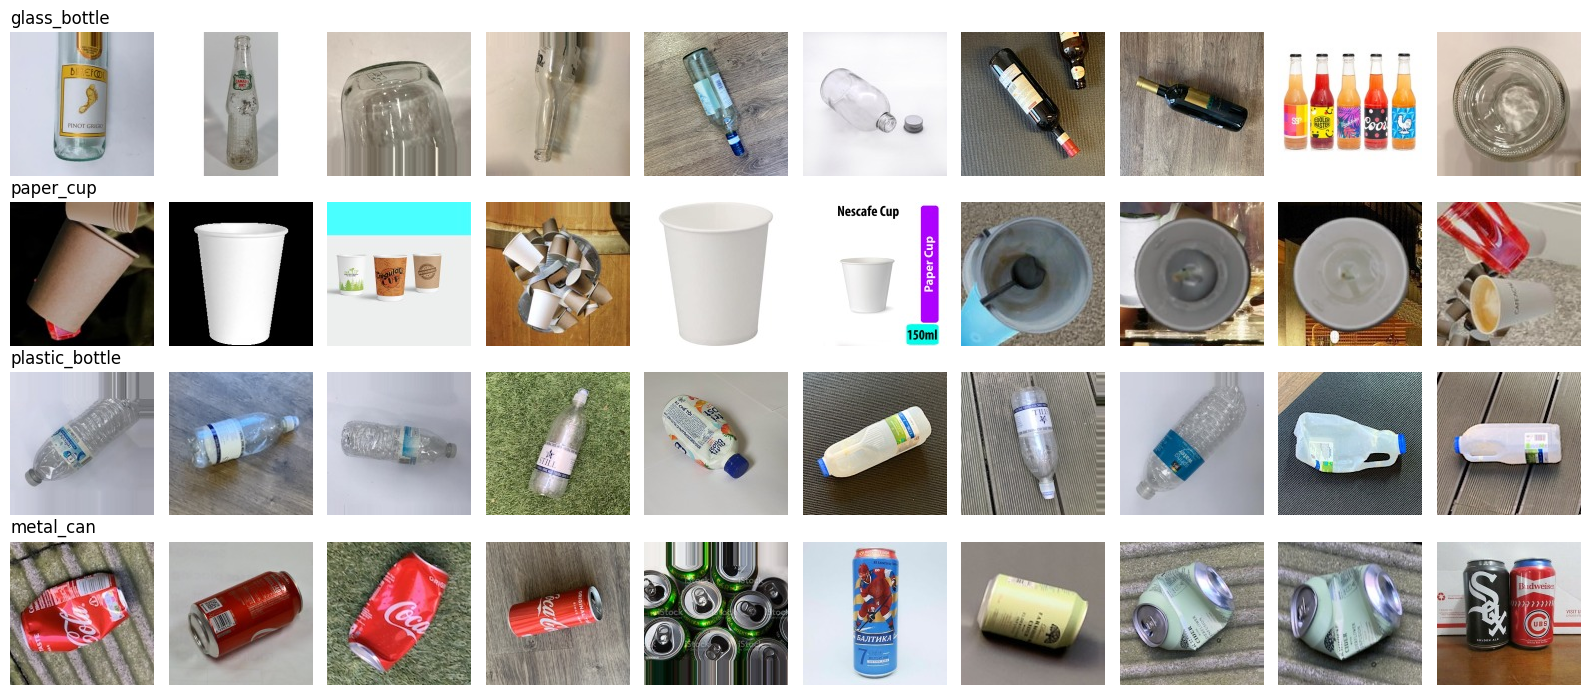

In [12]:
import glob, random, cv2, matplotlib.pyplot as plt
from wastesort.config import CLASSES
fig, ax = plt.subplots(4, 10, figsize=(16, 7))
for r, c in enumerate(CLASSES):
    for k, f in enumerate(random.sample(glob.glob(f"data/cls/train/{c}/*.jpg"), 10)):
        ax[r, k].imshow(cv2.imread(f)[:, :, ::-1]); ax[r, k].axis("off")
    ax[r, 0].set_title(c, loc="left")
plt.tight_layout(); plt.show()

## 3. Train the classifier

In [13]:
!python -m wastesort.train_classifier --data data --epochs 60

device=cuda  train=8082 val=1029 test=1097  weights=4.01M
epoch   1/60  loss 1.319  train 0.420  val 0.552  (19s)  <- best, saved
epoch   2/60  loss 1.171  train 0.528  val 0.691  (15s)  <- best, saved
epoch   3/60  loss 1.100  train 0.578  val 0.648  (15s)
epoch   4/60  loss 1.054  train 0.603  val 0.672  (15s)
epoch   5/60  loss 1.036  train 0.611  val 0.658  (15s)
epoch   6/60  loss 1.012  train 0.625  val 0.690  (15s)
epoch   7/60  loss 0.974  train 0.650  val 0.739  (15s)  <- best, saved
epoch   8/60  loss 0.954  train 0.668  val 0.724  (15s)
epoch   9/60  loss 0.949  train 0.665  val 0.707  (15s)
epoch  10/60  loss 0.911  train 0.696  val 0.707  (15s)
epoch  11/60  loss 0.890  train 0.707  val 0.769  (15s)  <- best, saved
epoch  12/60  loss 0.872  train 0.720  val 0.715  (16s)
epoch  13/60  loss 0.865  train 0.728  val 0.772  (15s)  <- best, saved
epoch  14/60  loss 0.851  train 0.734  val 0.794  (15s)  <- best, saved
epoch  15/60  loss 0.834  train 0.743  val 0.751  (15s)
epoch 

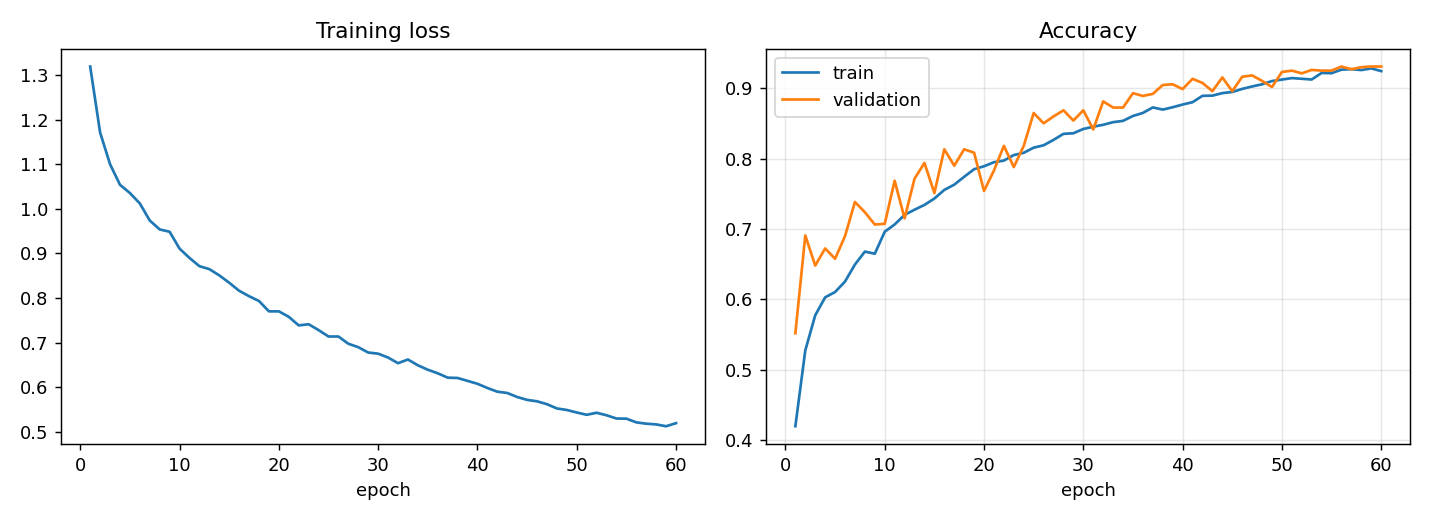

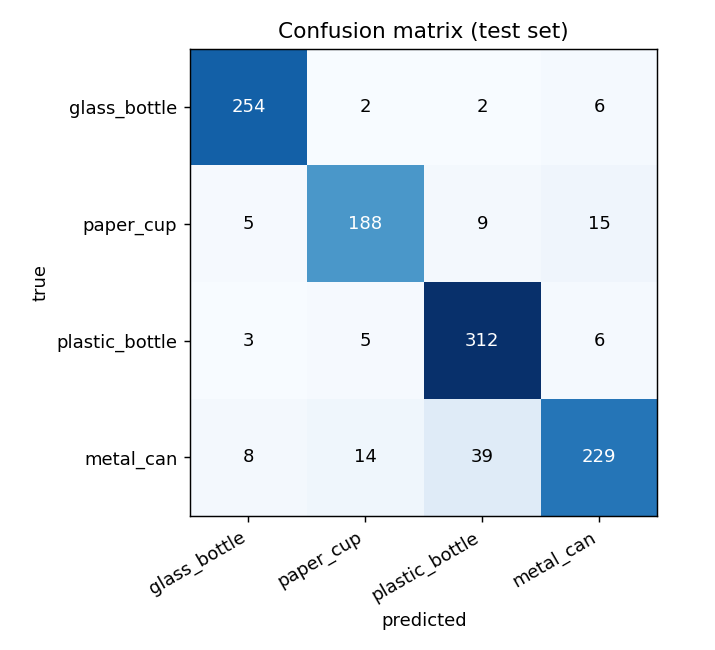

In [14]:
from IPython.display import Image, display
display(Image("runs/classifier/curves.png")); display(Image("runs/classifier/confusion_matrix.png"))

## 4. Train the detector

In [15]:
!python -m wastesort.train_detector --data data --epochs 80

device=cuda  train=6782 val=892 test=733  weights=4.51M
/kaggle/working/waste-sorter/wastesort/train_detector.py:131: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sched.step()
epoch   1/80  loss 16.370 (heat 14.655 box 0.703)  val AP50 0.050  P 0.203 R 0.145  (93s)  <- best, saved
epoch   2/80  loss 2.663 (heat 1.552 box 0.428)  val AP50 0.447  P 0.606 R 0.483  (89s)  <- best, saved
epoch   3/80  loss 1.958 (heat 1.056 box 0.332)  val AP50 0.581  P 0.792 R 0.529  (89s)  <- best, saved
epoch   4/80  loss 1.682 (heat 0.878 box 0.288)  val AP50 0.635  P 0.689 R 0.609  (88s)  <- best, saved
epoch   5/80  loss 1.483

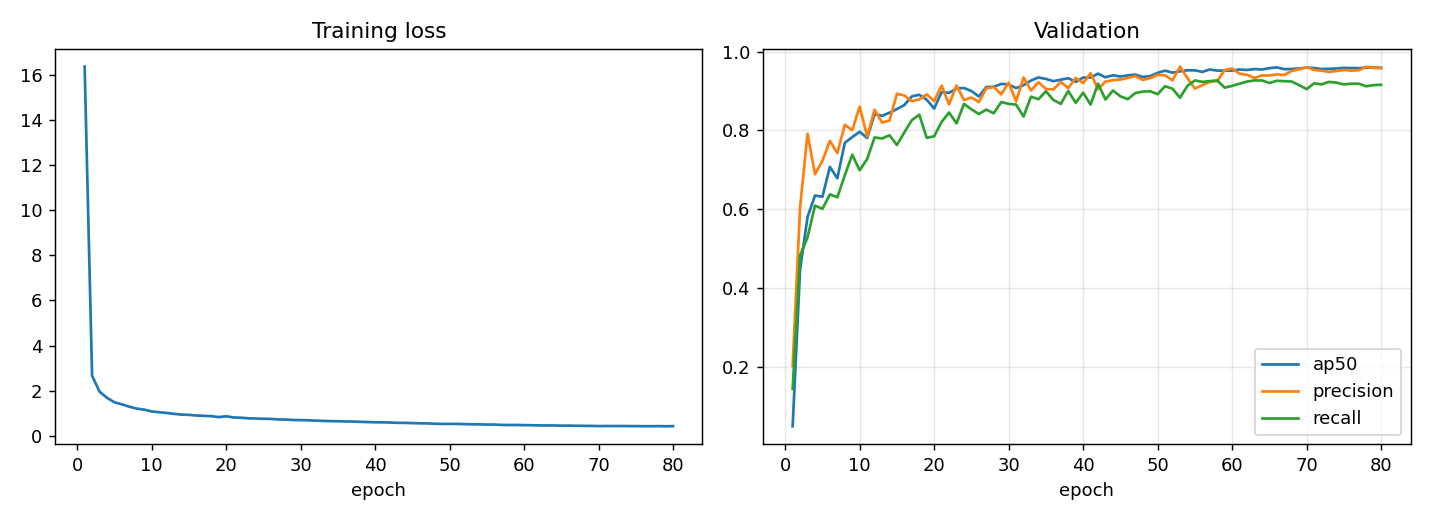

In [16]:
display(Image("runs/detector/curves.png"))

## 5. Test the whole pipeline on photos it has never seen

In [17]:
!python -m wastesort.evaluate --data data

photos: 733   objects: 1011   boxes drawn: 975
detector  recall    0.939   (objects that got a box)
detector  precision 0.973   (boxes that sit on a real object)
classifier accuracy on found objects   0.926
END-TO-END success (found AND right class) 0.907

class             objects   found  correct  success
glass_bottle          224     221      214    0.955
paper_cup              81      75       75    0.926
plastic_bottle        250     248      245    0.980
metal_can             188     184      140    0.745


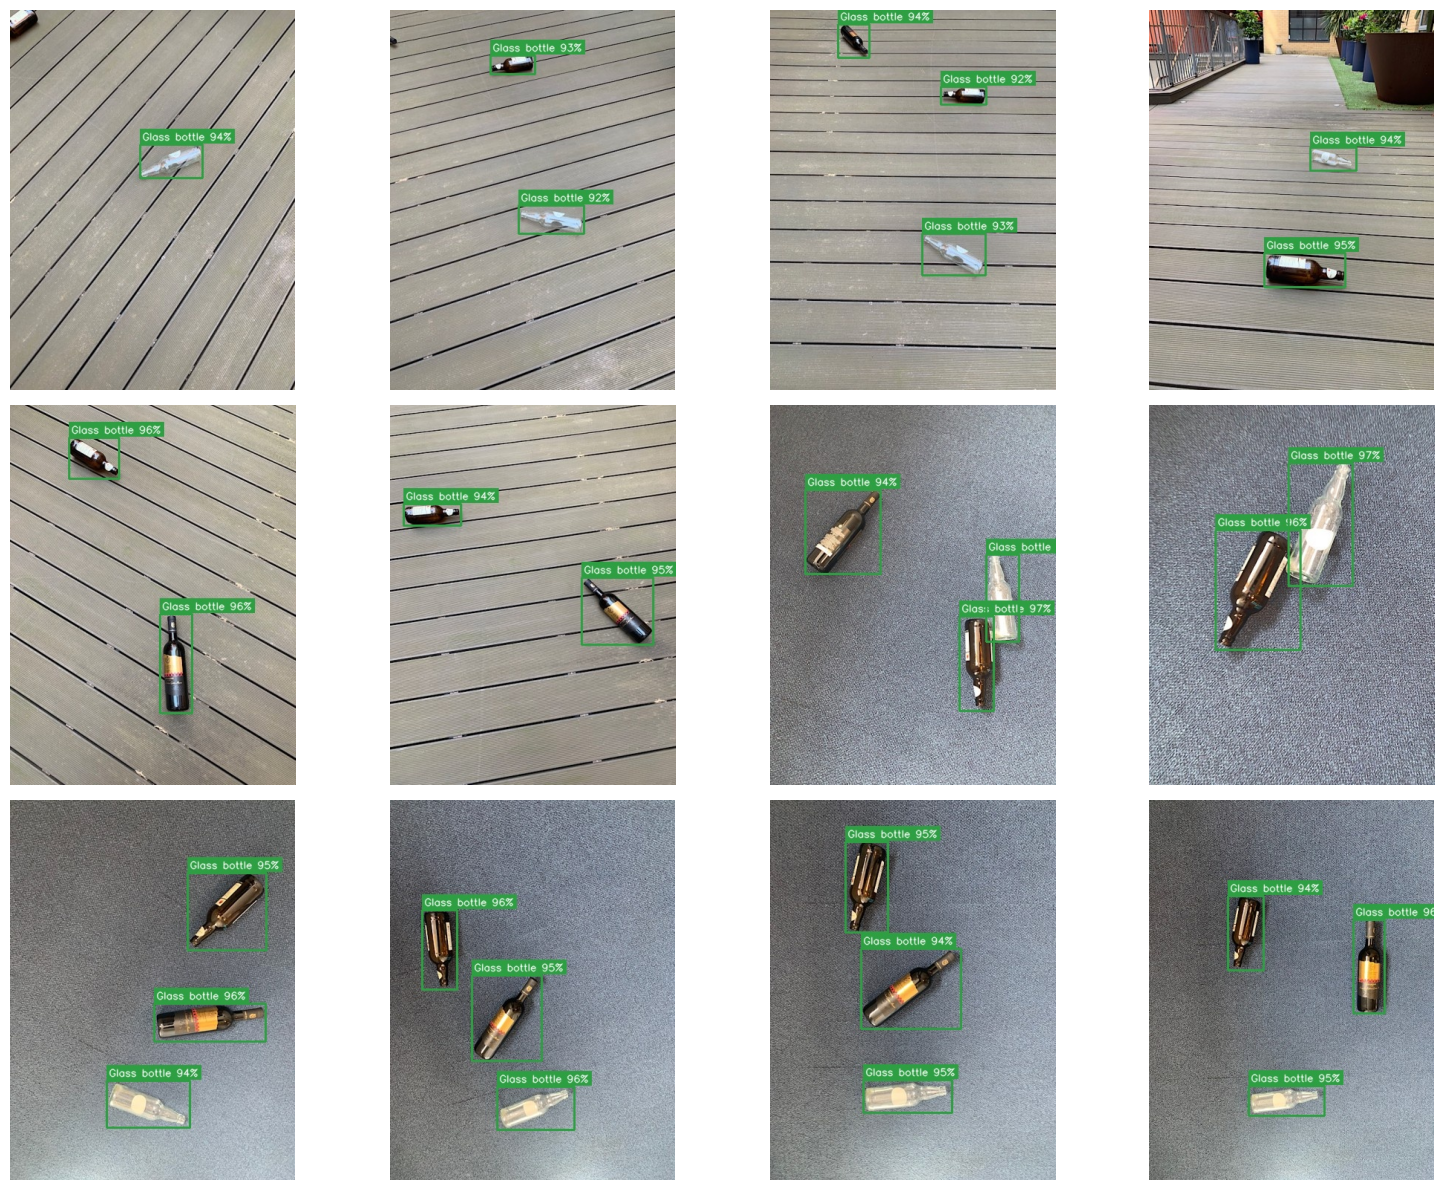

In [18]:
import glob
fig, ax = plt.subplots(3, 4, figsize=(16, 12))
for a, f in zip(ax.ravel(), sorted(glob.glob("runs/pipeline/example_*.jpg"))[-12:]):
    a.imshow(cv2.imread(f)[:, :, ::-1]); a.axis("off")
plt.tight_layout(); plt.show()

## 6. Pack the results
Download `waste_sorter_weights.zip`

In [19]:
import shutil
os.makedirs("export", exist_ok=True)
shutil.copytree("weights", "export/weights", dirs_exist_ok=True)
shutil.copytree("runs", "export/runs", dirs_exist_ok=True)
zip_path = shutil.make_archive(("/kaggle/working" if ON_KAGGLE else "/content") + "/waste_sorter_weights", "zip", "export")
print("Saved", zip_path)
if not ON_KAGGLE:
    from google.colab import files; files.download(zip_path)

Saved /kaggle/working/waste_sorter_weights.zip
